# 02. Tóm tắt Dữ liệu & Phân chia Tập dữ liệu (Data Splitting)

* **Sinh viên thực hiện:** Nguyễn Khắc Tuấn Đạt - BAI252094
* **Nhiệm vụ:** 
  1. Thống kê ngắn gọn số lượng mẫu có giá (`price`), thiếu giá và có nhãn điểm (`points`) từ dữ liệu đã qua làm sạch (không lặp lại báo cáo cleaning chi tiết).
  2. Phân chia các mẫu hợp lệ thành 3 tập `Train / Validation / Test` (tỷ lệ 70/15/15) theo nhóm tên chai rượu chuẩn hóa (`title_clean`).
  3. Kiểm tra đủ mẫu, không chồng nhóm tên chai và không thiếu giá/nhãn trong các tập xuất ra; giữ tập test cho bước đánh giá cuối.

BẢNG 1: KIỂM TRA TÌNH TRẠNG DỮ LIỆU ĐẦU VÀO (DATA AUDIT)


,Trạng thái dữ liệu,Số lượng (Bản ghi),Tỷ lệ (%),Đánh giá trạng thái
0,1. Tổng số bản ghi review (Từ Pipeline Cleaned),"119,988",100.00%,Tập đầu vào cho Data Split
1,2. Số bản ghi có nhãn điểm (points),"119,988",100.00%,Đạt chuẩn mục tiêu
2,3. Số bản ghi CÓ giá hợp lệ (price),"111,593",93.00%,Đạt chuẩn mục tiêu
3,4. Số bản ghi THIẾU giá (price = NaN),"8,395",7.00%,Giữ để audit; loại khỏi mẫu hồi quy theo giá


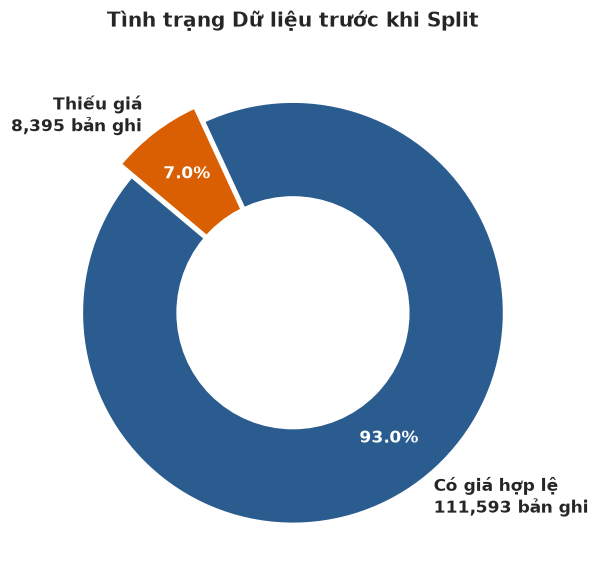

In [1]:
import os
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

# 0. Cấu hình hiển thị và ẩn các cảnh báo hệ thống không cần thiết
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Kế thừa dữ liệu đã được làm sạch (Cleaned Data) từ pipeline của nhóm
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == 'w5_progress_parts':
    PROJECT_ROOT = PROJECT_ROOT.parent.parent
elif PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

clean_path = PROJECT_ROOT / 'data' / 'processed' / 'wine_cleaned_final.csv'
if not clean_path.is_file():
    raise FileNotFoundError(f'Khong tim thay cleaned data: {clean_path}')
df_clean_input = pd.read_csv(clean_path)

# 2. Thống kê (Audit) tình trạng dữ liệu trước khi thực hiện chia tập
total_bottles = len(df_clean_input)
has_points = df_clean_input['points'].notna().sum()
has_price = df_clean_input['price'].notna().sum()
missing_price = df_clean_input['price'].isna().sum()

summary_df = pd.DataFrame({
    "Trạng thái dữ liệu": [
        "1. Tổng số bản ghi review (Từ Pipeline Cleaned)", 
        "2. Số bản ghi có nhãn điểm (points)", 
        "3. Số bản ghi CÓ giá hợp lệ (price)", 
        "4. Số bản ghi THIẾU giá (price = NaN)"
    ],
    "Số lượng (Bản ghi)": [
        f"{total_bottles:,}", 
        f"{has_points:,}", 
        f"{has_price:,}", 
        f"{missing_price:,}"
    ],
    "Tỷ lệ (%)": [
        "100.00%", 
        f"{(has_points/total_bottles)*100:.2f}%", 
        f"{(has_price/total_bottles)*100:.2f}%", 
        f"{(missing_price/total_bottles)*100:.2f}%"
    ],
    "Đánh giá trạng thái": [
        "Tập đầu vào cho Data Split",
        "Đạt chuẩn mục tiêu",
        "Đạt chuẩn mục tiêu",
        "Giữ để audit; loại khỏi mẫu hồi quy theo giá"
    ]
})

print("BẢNG 1: KIỂM TRA TÌNH TRẠNG DỮ LIỆU ĐẦU VÀO (DATA AUDIT)")
display(summary_df)

# 3. Biểu đồ Donut trực quan hóa dữ liệu (Tự động thích ứng với cấu trúc dữ liệu)
plt.close('all') # Xóa bộ nhớ đệm đồ họa cũ để tránh lỗi đè hình
fig, ax = plt.subplots(figsize=(7, 5.5))

# Thống kê giá trên toàn bộ cleaned data trước khi chọn mẫu mô hình
if missing_price > 0:
    sizes = [has_price, missing_price]
    labels = [f'Có giá hợp lệ\n{has_price:,} bản ghi', f'Thiếu giá\n{missing_price:,} bản ghi']
    colors = ['#2b5c8f', '#d95f02']
    explode = (0, 0.08)
else:
    sizes = [has_price]
    labels = [f'Có giá (100%)\n{has_price:,} bản ghi']
    colors = ['#2b5c8f']
    explode = None

wedges, texts, autotexts = ax.pie(
    sizes, 
    labels=labels, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    explode=explode,
    pctdistance=0.75,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

# Đổi màu chữ tỷ lệ % thành màu trắng cho hiển thị chuyên nghiệp
for autotext in autotexts:
    autotext.set_color('white')

# Vẽ vòng tròn trắng ở tâm tạo hiệu ứng Donut Chart
centre_circle = plt.Circle((0,0), 0.55, fc='white')
fig.gca().add_artist(centre_circle)

ax.set_title('Tình trạng Dữ liệu trước khi Split', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Nhận xét & Quy tắc chọn mẫu:
* Kế thừa trực tiếp `wine_cleaned_final.csv`: **119.988** dòng, tất cả có nhãn mục tiêu `points`.
* Có **111.593** dòng có giá quan sát và **8.395** dòng thiếu giá (khoảng **7%**). Cleaning giữ nguyên các giá trị thiếu để audit; không điền giá giả định.
* Bảng và hình trên dùng toàn bộ cleaned data. Trước khi chia tập, chỉ chọn các dòng có cả `price` và `points`; các dòng thiếu giá vẫn được giữ trong file cleaned gốc.

### Cấu hình chia tập:
Khánh chốt giữ **seed 42 ngày 21/10/2026** và phương pháp `GroupShuffleSplit` cho bộ chia hiện tại. Phần chọn mẫu/split đã hoàn thành; Spearman và mô hình dành cho buổi sau. EDA đã xem toàn mẫu có giá và dự án có ghi nhận holdout seed 42 từng được thử. Giữ seed 42 không xác nhận test hoàn toàn chưa từng được quan sát. Giữ lịch sử này khi diễn giải kết quả; không đổi seed để chọn kết quả thuận lợi và không tuning theo test.

Mau du dieu kien: 111,593; seed: 42
✅ KIỂM TRA KHÔNG CHỒNG NHÓM TÊN CHAI:
   • Giao tập hợp (Train ∩ Validation) : 0 nhóm trùng lặp
   • Giao tập hợp (Train ∩ Test)       : 0 nhóm trùng lặp
   • Giao tập hợp (Validation ∩ Test)  : 0 nhóm trùng lặp
   => Không có nhóm title_clean xuất hiện ở nhiều tập.

BẢNG 2: QUY MÔ VÀ KIỂM TRA GIÁ/NHÃN THIẾU SAU KHI CHIA


,Tập dữ liệu,Số dòng (Rows),Tỷ lệ (%),Số nhóm tên rượu (Groups),Số dòng thiếu price,Số dòng thiếu points
0,Train,78106,70.0%,"77,437",0,0
1,Validation,16745,15.0%,"16,594",0,0
2,Test,16742,15.0%,"16,594",0,0


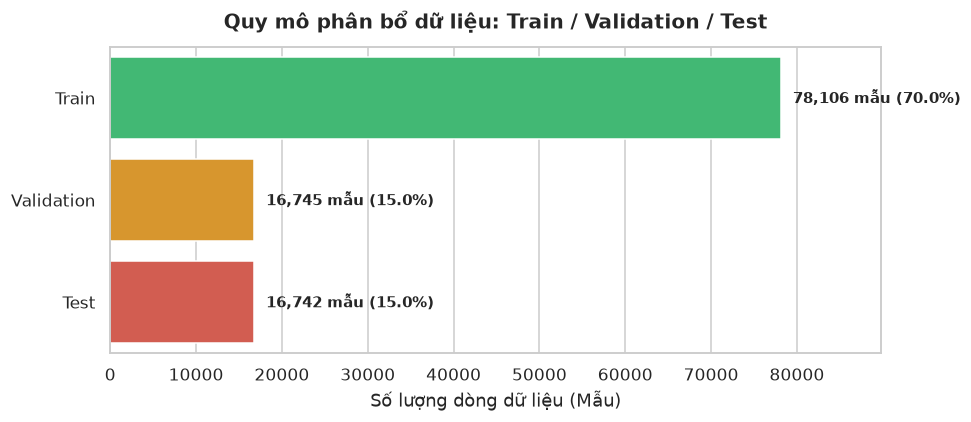

In [2]:
# 1. Lọc lấy các mẫu đủ điều kiện và chuẩn hóa tên chai (title_clean)
df_clean = df_clean_input.dropna(subset=['price', 'points']).copy()
assert len(df_clean) > 0, 'Khong co mau du dieu kien.'
assert df_clean['price'].gt(0).all(), 'Gia quan sat phai duong.'
assert not df_clean['price_was_missing'].any(), 'Mau mo hinh phai co gia quan sat.' 

def normalize_title(text):
    if pd.isna(text): 
        return "unknown"
    text = str(text).lower().strip()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^\w\s\(\)\-\']', '', text)
    return text.strip()

df_clean['title_clean'] = df_clean['title'].apply(normalize_title)
df_clean['log_price'] = np.log1p(df_clean['price']) # Tạo sẵn đặc trưng log_price cho mô hình Baseline

# 2. Chia tập bằng GroupShuffleSplit (xấp xỉ 70/15/15) theo title_clean
SEED = 42
gss_outer = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=SEED)
train_idx, temp_idx = next(gss_outer.split(df_clean, groups=df_clean['title_clean']))

df_train = df_clean.iloc[train_idx].copy()
df_temp = df_clean.iloc[temp_idx].copy()

gss_inner = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=SEED)
val_idx, test_idx = next(gss_inner.split(df_temp, groups=df_temp['title_clean']))

df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

# 3. Kiểm tra không chồng nhóm tên chai giữa các tập
train_groups = set(df_train['title_clean'])
val_groups = set(df_val['title_clean'])
test_groups = set(df_test['title_clean'])

overlap_tv = len(train_groups.intersection(val_groups))
overlap_tt = len(train_groups.intersection(test_groups))
overlap_vt = len(val_groups.intersection(test_groups))

assert overlap_tv == 0 and overlap_tt == 0 and overlap_vt == 0, "Co nhom title bi chong!"

# Mọi dòng đủ điều kiện xuất hiện đúng một lần; không fit preprocessing.
parts = {'train': df_train, 'val': df_val, 'test': df_test}
assigned_indices = pd.Index([index for part in parts.values() for index in part.index])
assert assigned_indices.is_unique, 'Co dong duoc chia vao nhieu tap.'
assert set(assigned_indices) == set(df_clean.index), 'Split bi thieu hoac thua mau.'
for name, part in parts.items():
    assert part[['price', 'points', 'log_price']].notna().all().all(), f'{name}: con gia/nhan thieu.'
    assert np.isfinite(part['log_price']).all(), f'{name}: log_price khong hop le.'
print(f'Mau du dieu kien: {len(df_clean):,}; seed: {SEED}')

print("✅ KIỂM TRA KHÔNG CHỒNG NHÓM TÊN CHAI:")
print(f"   • Giao tập hợp (Train ∩ Validation) : {overlap_tv} nhóm trùng lặp")
print(f"   • Giao tập hợp (Train ∩ Test)       : {overlap_tt} nhóm trùng lặp")
print(f"   • Giao tập hợp (Validation ∩ Test)  : {overlap_vt} nhóm trùng lặp")
print("   => Không có nhóm title_clean xuất hiện ở nhiều tập.\n")

# 4. Chỉ kiểm tra số mẫu và dữ liệu thiếu; không xem phân phối điểm của test
split_numeric = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test"],
    "Số dòng (Rows)": [len(df_train), len(df_val), len(df_test)],
    "Tỷ lệ (%)": [
        f"{len(df_train)/len(df_clean)*100:.1f}%", 
        f"{len(df_val)/len(df_clean)*100:.1f}%", 
        f"{len(df_test)/len(df_clean)*100:.1f}%"
    ],
    "Số nhóm tên rượu (Groups)": [f"{len(train_groups):,}", f"{len(val_groups):,}", f"{len(test_groups):,}"],
    "Số dòng thiếu price": [int(part['price'].isna().sum()) for part in parts.values()],
    "Số dòng thiếu points": [int(part['points'].isna().sum()) for part in parts.values()]
})

print("BẢNG 2: QUY MÔ VÀ KIỂM TRA GIÁ/NHÃN THIẾU SAU KHI CHIA")
display(split_numeric)

# 5. Biểu đồ thanh ngang (Đã fix triệt để FutureWarning của Seaborn v0.14+)
plt.figure(figsize=(9, 4))
ax = sns.barplot(
    x="Số dòng (Rows)", 
    y="Tập dữ liệu", 
    hue="Tập dữ liệu",
    data=split_numeric, 
    palette=["#2ECC71", "#F39C12", "#E74C3C"],
    legend=False
)
ax.set_title('Quy mô phân bổ dữ liệu: Train / Validation / Test', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Số lượng dòng dữ liệu (Mẫu)')
ax.set_ylabel('')
ax.set_xlim(0, len(df_train) * 1.15)

for p in ax.patches:
    width = int(p.get_width())
    pct = width / len(df_clean) * 100
    ax.annotate(f'{width:,} mẫu ({pct:.1f}%)', 
                (width, p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', xytext=(8, 0), 
                textcoords='offset points', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

In [3]:
# Xuất 3 tập dữ liệu ra thư mục chuẩn cho nhóm sử dụng
output_dir = PROJECT_ROOT / 'data' / 'processed' / 'splits'
os.makedirs(output_dir, exist_ok=True)

train_file = os.path.join(output_dir, 'train.csv')
val_file   = os.path.join(output_dir, 'val.csv')
test_file  = os.path.join(output_dir, 'test.csv')

df_train.to_csv(train_file, index=False, encoding='utf-8', lineterminator='\n')
df_val.to_csv(val_file, index=False, encoding='utf-8', lineterminator='\n')
df_test.to_csv(test_file, index=False, encoding='utf-8', lineterminator='\n')

print("📁 ĐÃ XUẤT THÀNH CÔNG CÁC FILE DỮ LIỆU ĐÃ CHIA:")
for name, path in [("Train", train_file), ("Validation", val_file), ("Test", test_file)]:
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"   • {name:<10}: {Path(path).relative_to(PROJECT_ROOT).as_posix()} ({size_mb:.2f} MB)")

📁 ĐÃ XUẤT THÀNH CÔNG CÁC FILE DỮ LIỆU ĐÃ CHIA:
   • Train     : data/processed/splits/train.csv (38.89 MB)
   • Validation: data/processed/splits/val.csv (8.33 MB)
   • Test      : data/processed/splits/test.csv (8.34 MB)


### Kết luận & Bàn giao:
1. **Chọn mẫu:** Chia **111.593** dòng có giá quan sát và nhãn `points`. **8.395** dòng thiếu giá vẫn nằm trong cleaned data để audit, không nằm trong ba file dùng cho thí nghiệm chính.
2. **Tính toàn vẹn:** Mỗi dòng đủ điều kiện xuất hiện đúng một lần. Các nhóm `title_clean` không chồng giữa train/validation/test; tỷ lệ dòng xấp xỉ 70/15/15. Kiểm tra này không thay thế yêu cầu chỉ fit preprocessing trên train ở bước mô hình.
3. **Bàn giao:** Ba CSV trong `data/processed/splits/` giữ metadata và các cột audit, kèm `title_clean` và `log_price`. Notebook không tính metric hay phân tích điểm của test. Seed 42 đã được Khánh chốt ngày 21/10/2026; giữ lịch sử sử dụng holdout khi diễn giải kết quả.

### Giới hạn:
Mẫu có giá chỉ chiếm khoảng 93% cleaned data và có thể không đại diện toàn bộ dữ liệu. Chưa kết luận các phân phối giống nhau chỉ từ số dòng hoặc tỷ lệ chia. Đây là bước chuẩn bị dữ liệu, chưa có kết quả kiểm định hay mô hình.